# Q1. Recommendation System

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt  
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer

# 2. Load datasets

In [6]:
orders = pd.read_csv("Dataset/orders.csv")
prior = pd.read_csv("Dataset/order_products__prior.csv")
products = pd.read_csv("Dataset/products.csv")
aisles = pd.read_csv("Dataset/aisles.csv")
departments = pd.read_csv("Dataset/departments.csv")

# 3. Explore dataset

In [7]:
print(orders.head())
print(prior.head())
print(aisles.head())
print(products.head())
print(departments.head())

   order_id  user_id eval_set  order_number  order_dow  order_hour_of_day  \
0   2539329        1    prior             1          2                  8   
1   2398795        1    prior             2          3                  7   
2    473747        1    prior             3          3                 12   
3   2254736        1    prior             4          4                  7   
4    431534        1    prior             5          4                 15   

   days_since_prior_order  
0                     NaN  
1                    15.0  
2                    21.0  
3                    29.0  
4                    28.0  
   order_id  product_id  add_to_cart_order  reordered
0         2       33120                  1          1
1         2       28985                  2          1
2         2        9327                  3          0
3         2       45918                  4          1
4         2       30035                  5          0
   aisle_id                       aisle
0    

# 4. Merge dataset

In [89]:
df = prior.merge(products, on="product_id", how="left")

df = df.merge(orders, on="order_id", how="left")

df = df.merge(aisles, on="aisle_id", how="left")

df = df.merge(departments, on="department_id", how="left")

df.head()

,order_id,product_id,add_to_cart_order,reordered,product_name,aisle_id,department_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,aisle,department
0,2,33120,1,1,Organic Egg Whites,86,16,202279,prior,3,5,9,8.0,eggs,dairy eggs
1,2,28985,2,1,Michigan Organic Kale,83,4,202279,prior,3,5,9,8.0,fresh vegetables,produce
2,2,9327,3,0,Garlic Powder,104,13,202279,prior,3,5,9,8.0,spices seasonings,pantry
3,2,45918,4,1,Coconut Butter,19,13,202279,prior,3,5,9,8.0,oils vinegars,pantry
4,2,30035,5,0,Natural Sweetener,17,13,202279,prior,3,5,9,8.0,baking ingredients,pantry


# 5. Select Required Columns

In [90]:
df = df[
    [
        "user_id",
        "order_id",
        "product_id",
        "product_name",
        "aisle",
        "department",
        "reordered",
    ]
]

df.head()

,user_id,order_id,product_id,product_name,aisle,department,reordered
0,202279,2,33120,Organic Egg Whites,eggs,dairy eggs,1
1,202279,2,28985,Michigan Organic Kale,fresh vegetables,produce,1
2,202279,2,9327,Garlic Powder,spices seasonings,pantry,0
3,202279,2,45918,Coconut Butter,oils vinegars,pantry,1
4,202279,2,30035,Natural Sweetener,baking ingredients,pantry,0


# 6. Data Quality check

In [91]:
print("Dataset shape:")
print(df.shape)

print("n\Dataset columns")
print(df.columns)

print("n\Dataset information")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

<>:4: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:7: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:4: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:7: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
/var/folders/6l/xq9knbhx4nd5l93yz02xxm300000gn/T/ipykernel_1319/3673428044.py:4: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
  print("n\Dataset columns")
/var/folders/6l/xq9knbhx4nd5l93yz02xxm300000gn/T/ipykernel_1319/3673428044.py:7: SyntaxWarning: "\D" is an invalid escape sequence.

Dataset shape:
(32434489, 7)
n\Dataset columns
Index(['user_id', 'order_id', 'product_id', 'product_name', 'aisle',
       'department', 'reordered'],
      dtype='str')
n\Dataset information
<class 'pandas.DataFrame'>
RangeIndex: 32434489 entries, 0 to 32434488
Data columns (total 7 columns):
 #   Column        Dtype
---  ------        -----
 0   user_id       int64
 1   order_id      int64
 2   product_id    int64
 3   product_name  str  
 4   aisle         str  
 5   department    str  
 6   reordered     int64
dtypes: int64(4), str(3)
memory usage: 1.7 GB
None

Missing values:
user_id         0
order_id        0
product_id      0
product_name    0
aisle           0
department      0
reordered       0
dtype: int64
nDuplicate rows:
0

Data types:
user_id         int64
order_id        int64
product_id      int64
product_name      str
aisle             str
department        str
reordered       int64
dtype: object


# 4. Merge datasets

In [92]:
df = prior.merge(products, on="product_id", how="left")
df = df.merge(orders, on="order_id", how="left")
df = df.merge(aisles, on="aisle_id", how="left")
df = df.merge(departments, on="department_id", how="left")

df.head()

,order_id,product_id,add_to_cart_order,reordered,product_name,aisle_id,department_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,aisle,department
0,2,33120,1,1,Organic Egg Whites,86,16,202279,prior,3,5,9,8.0,eggs,dairy eggs
1,2,28985,2,1,Michigan Organic Kale,83,4,202279,prior,3,5,9,8.0,fresh vegetables,produce
2,2,9327,3,0,Garlic Powder,104,13,202279,prior,3,5,9,8.0,spices seasonings,pantry
3,2,45918,4,1,Coconut Butter,19,13,202279,prior,3,5,9,8.0,oils vinegars,pantry
4,2,30035,5,0,Natural Sweetener,17,13,202279,prior,3,5,9,8.0,baking ingredients,pantry


# 5. Select Required Columns

In [93]:
df = df[
    [
        "user_id",
        "order_id",
        "product_id",
        "product_name",
        "aisle",
        "department",
        "reordered"
    ]
]

df.head()

,user_id,order_id,product_id,product_name,aisle,department,reordered
0,202279,2,33120,Organic Egg Whites,eggs,dairy eggs,1
1,202279,2,28985,Michigan Organic Kale,fresh vegetables,produce,1
2,202279,2,9327,Garlic Powder,spices seasonings,pantry,0
3,202279,2,45918,Coconut Butter,oils vinegars,pantry,1
4,202279,2,30035,Natural Sweetener,baking ingredients,pantry,0


# 6. Data Quality check

In [94]:
print("Dataset shape:")
print(df.shape)

print("\nDataset columns:")
print(df.columns)

print("\nDataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Dataset shape:
(32434489, 7)

Dataset columns:
Index(['user_id', 'order_id', 'product_id', 'product_name', 'aisle',
       'department', 'reordered'],
      dtype='str')

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 32434489 entries, 0 to 32434488
Data columns (total 7 columns):
 #   Column        Dtype
---  ------        -----
 0   user_id       int64
 1   order_id      int64
 2   product_id    int64
 3   product_name  str  
 4   aisle         str  
 5   department    str  
 6   reordered     int64
dtypes: int64(4), str(3)
memory usage: 1.7 GB
None

Missing values:
user_id         0
order_id        0
product_id      0
product_name    0
aisle           0
department      0
reordered       0
dtype: int64

Duplicate rows:
0

Data types:
user_id         int64
order_id        int64
product_id      int64
product_name      str
aisle             str
department        str
reordered       int64
dtype: object


# 7. Use Sample Data

In [95]:
df_sample = df.sample(n=100000, random_state=42)

print("Sample shape:", df_sample.shape)
df_sample.head()

Sample shape: (100000, 7)


,user_id,order_id,product_id,product_name,aisle,department,reordered
29481110,135284,3109255,34099,Crushed Red Chili Pepper,spices seasonings,pantry,0
2852353,7293,301098,41950,Organic Tomato Cluster,fresh vegetables,produce,0
11194500,111385,1181866,45066,Honeycrisp Apple,fresh fruits,produce,0
15909397,147365,1678630,8859,Natural Spring Water,water seltzer sparkling water,beverages,1
6101870,99290,644090,24781,"PODS Laundry Detergent, Ocean Mist Designed fo...",laundry,household,0


# 9. Exploratory Visualisation

# 9.1 Top 10 Purchased Products 

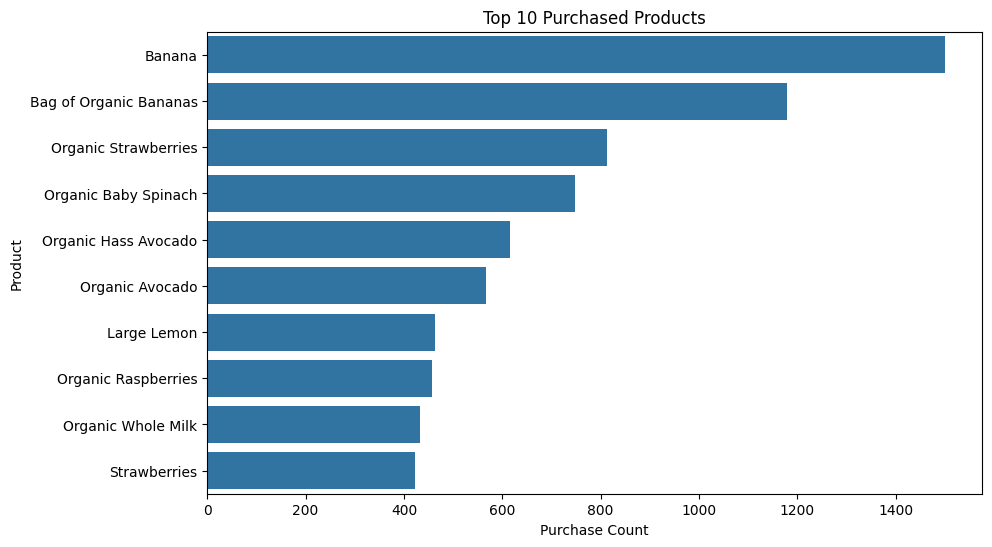

In [96]:
top_products = df_sample["product_name"].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_products.values, y=top_products.index)
plt.title("Top 10 Purchased Products")
plt.xlabel("Purchase Count")
plt.ylabel("Product")
plt.show()

# 9.2 Reordered vs Non-Reordered Products

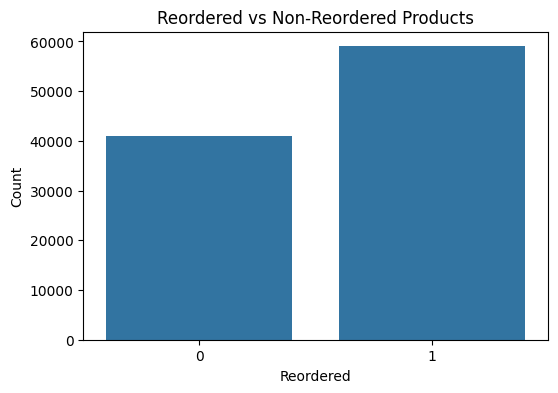

In [97]:
plt.figure(figsize=(6, 4))
sns.countplot(x="reordered", data=df_sample)
plt.title("Reordered vs Non-Reordered Products")
plt.xlabel("Reordered")
plt.ylabel("Count")
plt.show()

# 10. Content-Based Filtering

# 10.1 Create Product Features

In [98]:
product_features = df_sample[
    ["product_id", "product_name", "aisle", "department"]
].drop_duplicates()

product_features["combined_features"] = (
    product_features["product_name"].astype(str) + " " +
    product_features["aisle"].astype(str) + " " +
    product_features["department"].astype(str)
)
product_features.head()

,product_id,product_name,aisle,department,combined_features
29481110,34099,Crushed Red Chili Pepper,spices seasonings,pantry,Crushed Red Chili Pepper spices seasonings pantry
2852353,41950,Organic Tomato Cluster,fresh vegetables,produce,Organic Tomato Cluster fresh vegetables produce
11194500,45066,Honeycrisp Apple,fresh fruits,produce,Honeycrisp Apple fresh fruits produce
15909397,8859,Natural Spring Water,water seltzer sparkling water,beverages,Natural Spring Water water seltzer sparkling w...
6101870,24781,"PODS Laundry Detergent, Ocean Mist Designed fo...",laundry,household,"PODS Laundry Detergent, Ocean Mist Designed fo..."


# 10.2 TF-IDF Vectorisation

In [99]:
tfidf = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf.fit_transform(product_features["combined_features"])
print("TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF matrix shape: (16202, 5356)


# 10.3 Content Similarity Matrix

In [100]:
content_similarity = cosine_similarity(tfidf_matrix)
print("Content similarity matrix shape:", content_similarity.shape)

Content similarity matrix shape: (16202, 16202)


# 10.4 Content-Based Recommendation Function

In [101]:
def content_based_recommend(product_name, top_n=5):
    product_name = product_name.lower()
    product_list = product_features["product_name"].str.lower().tolist()

    if product_name not in product_list:
        return "Product not found in sample data."

    index = product_list.index(product_name)

    similarity_scores = list(enumerate(content_similarity[index]))
    similarity_scores = sorted(similarity_scores, key=lambda x: x[1], reverse=True)

    recommended_indices = [i[0] for i in similarity_scores[1:top_n + 1]]

    return product_features.iloc[recommended_indices][
        ["product_name", "aisle", "department"]
    ]

# 10.5 Test Content-Based Filtering

In [102]:
content_based_recommend("Banana", top_n=5)

,product_name,aisle,department
1809513,Organic Banana,fresh fruits,produce
30919947,Coconut,fresh fruits,produce
18331875,Blueberry,fresh fruits,produce
26152917,Mango,fresh fruits,produce
25187200,Lime,fresh fruits,produce


# 11. Prepare Data for Collaborative Filtering

# 11.1 Reduce Data Size for Collaborative Filtering

In [103]:
top_users = df_sample["user_id"].value_counts().head(500).index
top_products_cf = df_sample["product_name"].value_counts().head(500).index

cf_data = df_sample[
    (df_sample["user_id"].isin(top_users)) &
    (df_sample["product_name"].isin(top_products_cf))
]

print("Collaborative filtering data shape:", cf_data.shape)
print("Number of users:", cf_data["user_id"].nunique())
print("Number of products:", cf_data["product_name"].nunique())

Collaborative filtering data shape: (1723, 7)
Number of users: 474
Number of products: 421


# 11.2 Create User-Product Interaction Data

In [104]:
interaction_data = cf_data.groupby(
    ["user_id","product_name"]
).size().reset_index(name="interaction")

interaction_data.head()

,user_id,product_name,interaction
0,444,Bartlett Pears,1
1,444,Brussels Sprouts,1
2,444,Cucumber Kirby,1
3,444,Firm Tofu,1
4,444,Grated Parmesan,1


# 11.3 Create User-Item Matrix

In [105]:
user_item_matrix = interaction_data.pivot_table(
    index="user_id",
    columns="product_name",
    values="interaction",
    fill_value=0
)

print("User-item matrix shape:", user_item_matrix.shape)

user_item_matrix.head()

User-item matrix shape: (474, 421)


product_name,0% Greek Strained Yogurt,100 Calorie Per Bag Popcorn,100% Raw Coconut Water,100% Recycled Paper Towels,100% Whole Wheat Bread,2% Reduced Fat DHA Omega-3 Reduced Fat Milk,2% Reduced Fat Milk,2% Reduced Fat Organic Milk,85% Lean Ground Beef,Aged White Cheddar Baked Rice & Corn Puffs Gluten Free Lunch Packs,...,Whole Milk,Whole Milk Plain Yogurt,Whole Wheat Bread,XL Emerald White Seedless Grapes,Yellow Bell Pepper,Yellow Onions,YoBaby Peach Pear Yogurt,YoKids Blueberry & Strawberry/Vanilla Yogurt,"YoKids Squeezers Organic Low-Fat Yogurt, Strawberry","Yogurt, Strained Low-Fat, Coconut"
user_id,,,,,,,,,,,,,,,,,,,,,
444,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1197,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1424,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1563,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2335,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# 11.4 Validate User-Item Matrix

In [106]:
print("Total interactions:", user_item_matrix.values.sum())
print("Non-zero values:", (user_item_matrix.values > 0).sum())

Total interactions: 1723.0
Non-zero values: 1629


In [107]:
user_item_matrix.loc[
    user_item_matrix.sum(axis=1).sort_values(ascending=False).head(5).index
]

product_name,0% Greek Strained Yogurt,100 Calorie Per Bag Popcorn,100% Raw Coconut Water,100% Recycled Paper Towels,100% Whole Wheat Bread,2% Reduced Fat DHA Omega-3 Reduced Fat Milk,2% Reduced Fat Milk,2% Reduced Fat Organic Milk,85% Lean Ground Beef,Aged White Cheddar Baked Rice & Corn Puffs Gluten Free Lunch Packs,...,Whole Milk,Whole Milk Plain Yogurt,Whole Wheat Bread,XL Emerald White Seedless Grapes,Yellow Bell Pepper,Yellow Onions,YoBaby Peach Pear Yogurt,YoKids Blueberry & Strawberry/Vanilla Yogurt,"YoKids Squeezers Organic Low-Fat Yogurt, Strawberry","Yogurt, Strained Low-Fat, Coconut"
user_id,,,,,,,,,,,,,,,,,,,,,
97408,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
201623,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
132703,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
73080,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
100982,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# 12. User-User Collaborative Filtering

In [108]:
user_similarity = cosine_similarity(user_item_matrix)

user_similarity_df = pd.DataFrame(
    user_similarity,
    index=user_item_matrix.index,
    columns=user_item_matrix.index
)

user_similarity_df.head()

user_id,444,1197,1424,1563,2335,2663,3509,3536,3830,4356,...,200321,200505,201268,201444,201623,202593,203399,204315,204368,205754
user_id,,,,,,,,,,,,,,,,,,,,,
444,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.204124,0.0,0.0,0.136083,0.0,0.0,0.0,0.235702,0.0
1197,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0
1424,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0
1563,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.117851,0.0,0.0,0.0,0.000000,0.0
2335,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0


# 12.2 User-User Recommendation Function

In [109]:
def user_user_recommend(user_id, top_n=5):
    if user_id not in user_similarity_df.index:
        return []

    similar_users = user_similarity_df[user_id].sort_values(ascending=False)[1:6]
    similar_user_ids = similar_users.index

    products_bought_by_user = set(
        user_item_matrix.loc[user_id][user_item_matrix.loc[user_id] > 0].index
    )

    similar_users_products = user_item_matrix.loc[
        similar_user_ids
    ].sum().sort_values(ascending=False)

    recommendations = [
        product for product in similar_users_products.index
        if product not in products_bought_by_user
    ]

    return recommendations[:top_n]

# 12.3 Test User-User Recommendation

In [110]:
sample_user = user_item_matrix.index[0]

print("User ID:", sample_user)
print("User-user recommendations:")
print(user_user_recommend(sample_user, top_n=5))

User ID: 444
User-user recommendations:
['Organic Avocado', 'Milk, Organic, Vitamin D', 'Honey Nut Cheerios', 'Organic Beef Hot Dogs', 'Fresh Ginger Root']


# 13. Item-Item Collaborative Filtering


# 13.1 Item Similarity Matrix

In [111]:
item_similarity = cosine_similarity(user_item_matrix.T)

item_similarity_df = pd.DataFrame(
    item_similarity,
    index=user_item_matrix.columns,
    columns=user_item_matrix.columns
)

item_similarity_df.head()

product_name,0% Greek Strained Yogurt,100 Calorie Per Bag Popcorn,100% Raw Coconut Water,100% Recycled Paper Towels,100% Whole Wheat Bread,2% Reduced Fat DHA Omega-3 Reduced Fat Milk,2% Reduced Fat Milk,2% Reduced Fat Organic Milk,85% Lean Ground Beef,Aged White Cheddar Baked Rice & Corn Puffs Gluten Free Lunch Packs,...,Whole Milk,Whole Milk Plain Yogurt,Whole Wheat Bread,XL Emerald White Seedless Grapes,Yellow Bell Pepper,Yellow Onions,YoBaby Peach Pear Yogurt,YoKids Blueberry & Strawberry/Vanilla Yogurt,"YoKids Squeezers Organic Low-Fat Yogurt, Strawberry","Yogurt, Strained Low-Fat, Coconut"
product_name,,,,,,,,,,,,,,,,,,,,,
0% Greek Strained Yogurt,1.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0
100 Calorie Per Bag Popcorn,0.0,1.0,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0
100% Raw Coconut Water,0.0,0.0,1.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0
100% Recycled Paper Towels,0.0,0.0,0.0,1.0,0.0,0.00000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0
100% Whole Wheat Bread,0.0,0.0,0.0,0.0,1.0,0.27735,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.083624,0.0,0.0,0.0,0.0


# 13.2 Product-to-Product Recommendation Function

In [112]:
def item_item_recommend(product_name, top_n=5):
    if product_name not in item_similarity_df.index:
        return "Product not found in sample data."

    similar_items = item_similarity_df[product_name].sort_values(
        ascending=False
    )[1:top_n + 1]

    return similar_items

# 13.3 Test Product-to-Product Recommendation

In [113]:
item_item_recommend("Banana", top_n=5)

product_name
Feta Cheese Crumbles           0.178174
Sparkling Water Berry          0.178174
No Salt Added Black Beans      0.178174
Organic Reduced Fat 2% Milk    0.168359
Organic Whole Cashews          0.145479
Name: Banana, dtype: float64

# 13.4 Item-Item Recommendation for a User

In [114]:
def item_item_user_recommend(user_id, top_n=5):
    if user_id not in user_item_matrix.index:
        return []

    user_products = user_item_matrix.loc[user_id]
    bought_products = user_products[user_products > 0].index.tolist()

    scores = pd.Series(dtype=float)

    for product in bought_products:
        if product in item_similarity_df.index:
            scores = pd.concat([scores, item_similarity_df[product]])

    if scores.empty:
        return[]

    scores = scores.groupby(scores.index).mean()
    scores = scores.drop(labels=bought_products, errors="ignore")
    scores = scores.sort_values(ascending=False)   

    return scores.head(top_n).index.tolist()

# 13.5 Test Item-Item User Recommendation

In [115]:
print("User ID:", sample_user)
print("Item-item user recommendations:")
print(item_item_user_recommend(sample_user, top_n=5))

User ID: 444
Item-item user recommendations:
['Sinfully Sweet Campari Tomatoes', 'Organic Spring Mix', 'Organic Extra Virgin Olive Oil', 'Fresh Ginger Root', 'Spring Water']


# 14. Leave-One-Product-Out Evaluation

In [116]:
# Select users who purchased at least 2 products
eligible_users = user_item_matrix[user_item_matrix.gt(0).sum(axis=1) >= 2].index[:100]

print("Number of eligible users:", len(eligible_users))

Number of eligible users: 100


In [117]:
# Create train matrix and hidden test items
train_matrix = user_item_matrix.copy()
hidden_items = {}

for user in eligible_users:
    user_products = train_matrix.loc[user][train_matrix.loc[user] > 0].index.tolist()

    hidden_product = user_products[-1]
    hidden_items[user] = hidden_product

    train_matrix.loc[user] = hidden_product = 0 

print("Hidden test items created:", len(hidden_items))

Hidden test items created: 100


# 14.1 Recalculate Similarity Matrices

In [118]:
train_user_similarity = cosine_similarity(train_matrix)

train_user_similarity_df = pd.DataFrame(
    train_user_similarity,
    index=train_matrix.index,
    columns=train_matrix.index
)

train_item_similarity = cosine_similarity(train_matrix.T)

train_item_similarity_df = pd.DataFrame(
    train_item_similarity,
    index=train_matrix.columns,
    columns=train_matrix.columns
)

# 14.2 User-User Recommendation for Evaluation

In [119]:
def user_user_recommend_eval(user_id, top_n=5):
    if user_id not in train_user_similarity_df.index:
        return []

    similar_users = train_user_similarity_df[user_id].sort_values(ascending=False)[1:6]
    similar_user_ids = similar_users.index

    products_bought_by_user = set(
        train_matrix.loc[user_id][train_matrix.loc[user_id] > 0].index
    )

    similar_users_products = train_matrix.loc[
        similar_user_ids
    ].sum().sort_values(ascending=False)

    recommendations = [
        product for product in similar_users_products.index
        if product not in products_bought_by_user
    ]

    return recommendations[:top_n]

# 14.3 Item-Item Recommendation for Evaluation

In [120]:
def item_item_user_recommend_eval(user_id, top_n=5):
    if user_id not in train_matrix.index:
        return []

    user_products = train_matrix.loc[user_id]
    bought_products = user_products[user_products > 0].index.tolist()

    scores = pd.Series(dtype=float)

    for product in bought_products:
        if product in train_item_similarity_df.index:
            scores = pd.concat([scores, train_item_similarity_df[product]])

    if scores.empty:
        return []

    scores = scores.groupby(scores.index).mean()
    scores = scores.drop(labels=bought_products, errors="ignore")
    scores = scores.sort_values(ascending=False)

    return scores.head(top_n).index.tolist()

# 15. Evaluate Models

In [123]:
def hit_rate_at_k(recommended_items, hidden_item, k=5):
    recommended_items = recommended_items[:k]
    return 1 if hidden_item in recommended_items else 0

In [124]:
user_user_hits = []
item_item_hits = []

for user, hidden_item in hidden_items.items():
    user_recs = user_user_recommend_eval(user, top_n=5)
    item_recs = item_item_user_recommend_eval(user, top_n=5)

    user_user_hits.append(hit_rate_at_k(user_recs, hidden_item, k=5))
    item_item_hits.append(hit_rate_at_k(item_recs, hidden_item, k=5))

user_user_hit_rate = np.mean(user_user_hits)
item_item_hit_rate = np.mean(item_item_hits)

print("User-User Hit Rate@5:", user_user_hit_rate)
print("Item-Item Hit Rate@5:", item_item_hit_rate)

User-User Hit Rate@5: 0.02
Item-Item Hit Rate@5: 0.0


# 16. Evaluation Visualisation

In [126]:
evaluation_summary = pd.DataFrame({
    "Model": [
        "User-User Collaborate Filtering",
        "Item-Item Collaborate Filtering"
    ],
    "Hit Rate@5": [
        user_user_hit_rate,
        item_item_hit_rate
    ]
})

evaluation_summary 

,Model,Hit Rate@5
0,User-User Collaborate Filtering,0.02
1,Item-Item Collaborate Filtering,0.00
